# MSDS 565 — Unit 1, Notebook 1: Exploratory Data Analysis
### Car Sales (US Used Cars) — Team DataStars

Purpose. Understand the raw data before any cleaning: structure, distributions, what relates to
price, and every data quality problem Notebook 2 will need to fix.

Scope. Read-only. Nothing is imputed, dropped, parsed, or encoded here. Problems we find are
collected into a Data Quality Register in §7, which is the hand-off to preprocessing.

Target variable. price (regression).

## 1. Setup and data load

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

# The raw CSV lives in the shared class data folder, not in this repo (~1 GB, over GitHub's 100 MB
# limit). Each team member points DATA_PATH at their own local copy.
DATA_PATH = Path("/Users/ironcloth/Documents/MSDS-565-main/Datasets/CarSales_Large.csv")

# low_memory=False: the file is wide with many sparse object columns, and chunked type inference
# otherwise produces inconsistent dtypes across chunks.
df = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")

Rows: 302,590   Columns: 66


## 2. Structure: dtypes, missing values, cardinality

In [2]:
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(dropna=True),
}).sort_values("pct_missing", ascending=False)

overview

,dtype,n_missing,pct_missing,n_unique
vehicle_damage_category,float64,302590,100.00,0
combine_fuel_economy,float64,302590,100.00,0
is_certified,float64,302590,100.00,0
bed,object,300273,99.23,3
cabin,object,297035,98.16,4
...,...,...,...,...
is_new,bool,0,0.00,2
franchise_dealer,bool,0,0.00,2
dealer_zip,int64,0,0.00,664
daysonmarket,int64,0,0.00,1035


Three patterns matter here, and none of them are "missing at random":

- 3 columns are 100% empty — combine_fuel_economy, is_certified, vehicle_damage_category.
  They are typed float64 only because every value is NaN.
- 6 columns are missing at exactly 46.10% — fleet, frame_damaged, has_accidents, isCab,
  salvage, theft_title. An identical rate across unrelated fields means one vehicle-history report
  was not pulled for ~139k listings. Notebook 2 should encode "no report" as its own level, not impute False.
- Truck-only fields are 87–99% missing — bed, bed_height, bed_length, cabin. A sedan has no
  truck bed, so this is structurally missing and equally meaningful.

Cardinality splits the object columns cleanly: a few genuine categoricals (body_type 9, fuel_type 7)
against a long tail of free text (description has 260,806 distinct values).

## 3. Which columns are useless for predicting price?

In [3]:
useless = pd.DataFrame([
    ("Unnamed: 0",              "Row-index artifact from a previous export."),
    ("listing_id, sp_id",       "Unique keys — memorise rows, cannot generalise."),
    ("main_picture_url",        "URL, 254,865 distinct values; no signal without image modelling."),
    ("description",             "Free-text ad copy, 260,806 distinct values; needs NLP, not tabular encoding."),
    ("combine_fuel_economy, is_certified, vehicle_damage_category", "100% missing."),
    ("bed_height",              "Only non-null value is the placeholder '--' — effectively 100% missing."),
    ("dealer_zip",              "Read as int64, so ZIP is treated as a magnitude; lat/long already encode location."),
    ("wheel_system_display",    "Verbatim restatement of wheel_system ('AWD' vs 'All-Wheel Drive')."),
    ("savings_amount",          "Dealer discount vs list price — derived from price, so label leakage."),
], columns=["column", "reason"])

useless

,column,reason
0,Unnamed: 0,Row-index artifact from a previous export.
1,"listing_id, sp_id","Unique keys — memorise rows, cannot generalise."
2,main_picture_url,"URL, 254,865 distinct values; no signal withou..."
3,description,"Free-text ad copy, 260,806 distinct values; ne..."
4,"combine_fuel_economy, is_certified, vehicle_da...",100% missing.
5,bed_height,Only non-null value is the placeholder '--' — ...
6,dealer_zip,"Read as int64, so ZIP is treated as a magnitud..."
7,wheel_system_display,Verbatim restatement of wheel_system ('AWD' vs...
8,savings_amount,Dealer discount vs list price — derived from p...


savings_amount is the one to watch: it is computed from the asking price, so including it would
leak the target — which the brief explicitly forbids.

## 4. Data quality issues

Five classes of problem, each collected into the register in §7.

### 4.1 -- used as a hidden missing-value placeholder

In [4]:
placeholders = {c: int((df[c] == "--").sum())
                for c in df.select_dtypes("object").columns if (df[c] == "--").any()}

pd.Series(placeholders, name="n_rows_equal_to_'--'").sort_values(ascending=False)

bed_height          37879
back_legroom         8750
front_legroom        2287
bed_length            896
fuel_tank_volume      128
maximum_seating        44
width                  42
height                 40
length                 40
wheelbase              38
Name: n_rows_equal_to_'--', dtype: int64

The most dangerous issue in the dataset, because isna() does not count these. §2 reports
back_legroom as 5.25% missing when the true figure is higher once its 8,750 "--" values are added.
Any dropna()/fillna() in Notebook 2 sails straight past them, and they then break the numeric
parse in §4.2. bed_height is the extreme case: all of its non-null values are "--".

### 4.2 Numbers stored as strings

In [5]:
unit_cols = ["back_legroom", "front_legroom", "fuel_tank_volume", "height",
             "length", "wheelbase", "width", "maximum_seating"]

print("Measurements with the unit glued on:")
for c in unit_cols:
    print(f"  {c:18s} {df[c].dtype}  e.g. {df[c].dropna().unique()[:2].tolist()}")

print("\nTwo values packed into one string:")
print(df[["power", "torque"]].dropna().head(2).to_string(index=False))

Measurements with the unit glued on:
  back_legroom       object  e.g. ['34.4 in', '37.9 in']
  front_legroom      object  e.g. ['42.9 in', '42.4 in']
  fuel_tank_volume   object  e.g. ['24.6 gal', '17.4 gal']
  height             object  e.g. ['75.2 in', '57.2 in']
  length             object  e.g. ['200 in', '193.8 in']
  wheelbase          object  e.g. ['112.2 in', '116 in']
  width              object  e.g. ['78 in', '80.3 in']
  maximum_seating    object  e.g. ['8 seats', '5 seats']

Two values packed into one string:
             power                torque
383 hp @ 5,600 RPM 403 lb-ft @ 3,600 RPM
335 hp @ 5,600 RPM 405 lb-ft @ 2,400 RPM


Ten columns are unusable as loaded. Eight are continuous measurements typed object because the unit
is attached ("34.4 in", "24.6 gal") — so they were excluded from every numeric summary and
correlation in this notebook, meaning §6 is missing eight real predictors. Parsing them must handle the
"--" values from §4.1 first or the cast will raise.

power and torque each hold two measurements plus a thousands separator: "383 hp @ 5,600 RPM" is
peak output and the RPM at which it is reached. Note horsepower already exists as a clean float,
so the RPM half is the genuinely new information.

### 4.3 Boolean flags stored three different ways

In [6]:
flag_cols = ["is_new", "franchise_dealer", "fleet", "salvage", "has_accidents",
             "is_cpo", "is_oemcpo", "is_certified"]

pd.DataFrame({
    "dtype": df[flag_cols].dtypes.astype(str),
    "non_null_values": [sorted(map(str, df[c].dropna().unique()))[:3] for c in flag_cols],
    "pct_missing": (df[flag_cols].isna().mean() * 100).round(2),
})

,dtype,non_null_values,pct_missing
is_new,bool,"[False, True]",0.00
franchise_dealer,bool,"[False, True]",0.00
fleet,object,"[False, True]",46.10
salvage,object,"[False, True]",46.10
has_accidents,object,"[False, True]",46.10
is_cpo,object,[True],94.78
is_oemcpo,object,[True],96.30
is_certified,float64,[],100.00


The same yes/no concept is stored as a true bool (is_new), as object holding Python bools plus
NaN (fleet, salvage, has_accidents — the 46.10% block from §2), and as float64 because it is
empty (is_certified). The values are real booleans, not the strings "True"/"False", so they only
need the null decision resolved before casting.

is_cpo/is_oemcpo are one-sided — True or nothing — so for those two specifically NaN means
False, a different rule than for fleet/salvage.

### 4.4 Impossible numeric values

In [7]:
print("mileage  — max:", f"{df['mileage'].max():,.0f}",
      "| rows > 500,000:", (df["mileage"] > 500_000).sum(),
      "| 99.9th pct:", f"{df['mileage'].quantile(0.999):,.0f}")

clean = df[df["mileage"] < 500_000]
impact = pd.DataFrame({
    "with 2 sentinel rows": [df["mileage"].std(), df["price"].corr(df["mileage"])],
    "without them":         [clean["mileage"].std(), clean["price"].corr(clean["mileage"])],
}, index=["std mileage", "corr(price, mileage)"]).round(3)
print("\n", impact.to_string())

print("\ncity_fuel_economy > 60 mpg:", (df["city_fuel_economy"] > 60).sum(),
      "| exactly 127:", (df["city_fuel_economy"] == 127).sum())
print(df.loc[df["city_fuel_economy"] > 60, "fuel_type"].value_counts().head(2).to_string())

mileage  — max: 99,999,988 | rows > 500,000: 2 | 99.9th pct: 264,356

                       with 2 sentinel rows  without them
std mileage                     192778.059     46620.221
corr(price, mileage)                -0.106        -0.445

city_fuel_economy > 60 mpg: 1261 | exactly 127: 442
fuel_type
Electric    1187
Gasoline      74


Mileage. The maximum is 99,999,988 — an odometer sentinel, not a real car. Only 2 rows exceed
500k miles, which makes them easy to dismiss, but they do enormous damage: the standard deviation
collapses from 192,778 to 46,620 once they go (three quarters of the apparent spread is those two
rows, and StandardScaler divides by exactly that number), and the correlation with price moves from
-0.11 to -0.45. Points that far out have huge leverage on Pearson's r and were flattening a strong
relationship into near-noise. The lesson for Notebook 2: outlier severity is about leverage, not row
count — dropping these costs 0.0007% of the data and recovers a good predictor.

Fuel economy. Mostly benign — 1,187 of the 1,261 rows above 60 mpg are electric, where MPGe really
does reach triple digits. The real problems are the 74 gasoline cars claiming >60 mpg and the 442
rows sitting at exactly 127, which looks like a capped value.

### 4.5 Duplicates, contradictions, and formatting

In [8]:
print("Duplicate rows ignoring Unnamed: 0 / listing_id:",
      df.drop(columns=["Unnamed: 0", "listing_id"]).duplicated().sum())
print("Duplicated listing_id                          :", df.duplicated("listing_id").sum())
print("is_new=True but mileage > 1,000                :", int(((df["is_new"]) & (df["mileage"] > 1000)).sum()))
print("listing_color literally 'UNKNOWN'              :", (df["listing_color"] == "UNKNOWN").sum())
print("listed_date dtype                              :", df["listed_date"].dtype, "| e.g.", df["listed_date"].iloc[0])
print("exterior_color distinct free-text values       :", df["exterior_color"].nunique())

Duplicate rows ignoring Unnamed: 0 / listing_id: 1210
Duplicated listing_id                          : 3
is_new=True but mileage > 1,000                : 4406
listing_color literally 'UNKNOWN'              : 38740
listed_date dtype                              : object | e.g. 2020-07-08
exterior_color distinct free-text values       : 7604


1,210 rows are exact content duplicates once the two key columns are ignored (no row is
byte-identical because Unnamed: 0 makes each unique). Left in, they get double weight and can
straddle the train/test split, leaking test rows into training — so deduplication must happen before
the split.

4,406 cars are flagged new while showing over 1,000 miles, a dealer-entry inconsistency. Small
relative to 302k rows, but it means is_new and mileage disagree often enough that neither should be
derived from the other.

Formatting. listed_date is an unparsed string; listing_color hides missingness as the literal
"UNKNOWN" on 38,740 rows (the same trap as "--"); and exterior_color has 7,604 free-text values
because dealers type "Nebula Gray Pearl" instead of picking from a list — the clean 15-value
listing_color is the normalised version of that same information. make_name has no misspellings:
its 74 values are all real brands, and the odd casing (INFINITI, smart, RAM) is each brand's own
styling.

## 5. Univariate distributions

### 5.1 Numeric columns

In [9]:
# Identifiers and empty columns would only add noise.
exclude = ["Unnamed: 0", "listing_id", "sp_id", "dealer_zip",
           "combine_fuel_economy", "is_certified", "vehicle_damage_category"]
num_cols = [c for c in df.select_dtypes("number").columns if c not in exclude]

df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
city_fuel_economy,255261.0,22.89,8.89,8.00,18.00,22.00,26.00,127.00
daysonmarket,302590.0,72.19,105.81,0.00,14.00,34.00,77.00,2416.00
engine_displacement,285071.0,2932.35,1322.87,700.00,2000.00,2500.00,3600.00,8400.00
highway_fuel_economy,255261.0,29.80,7.91,11.00,25.00,29.00,34.00,127.00
horsepower,285071.0,245.67,90.98,67.00,172.00,241.00,300.00,1001.00
latitude,302590.0,33.76,4.48,25.60,29.77,33.51,37.33,45.64
longitude,302590.0,-93.52,11.76,-123.01,-98.55,-95.41,-82.51,-69.81
mileage,285616.0,33446.43,192778.06,0.00,7.00,12410.00,46393.25,99999988.00
owner_count,154701.0,1.60,1.00,1.00,1.00,1.00,2.00,13.00
price,302590.0,29124.56,20462.59,386.90,17420.00,25097.00,37070.00,1750000.00


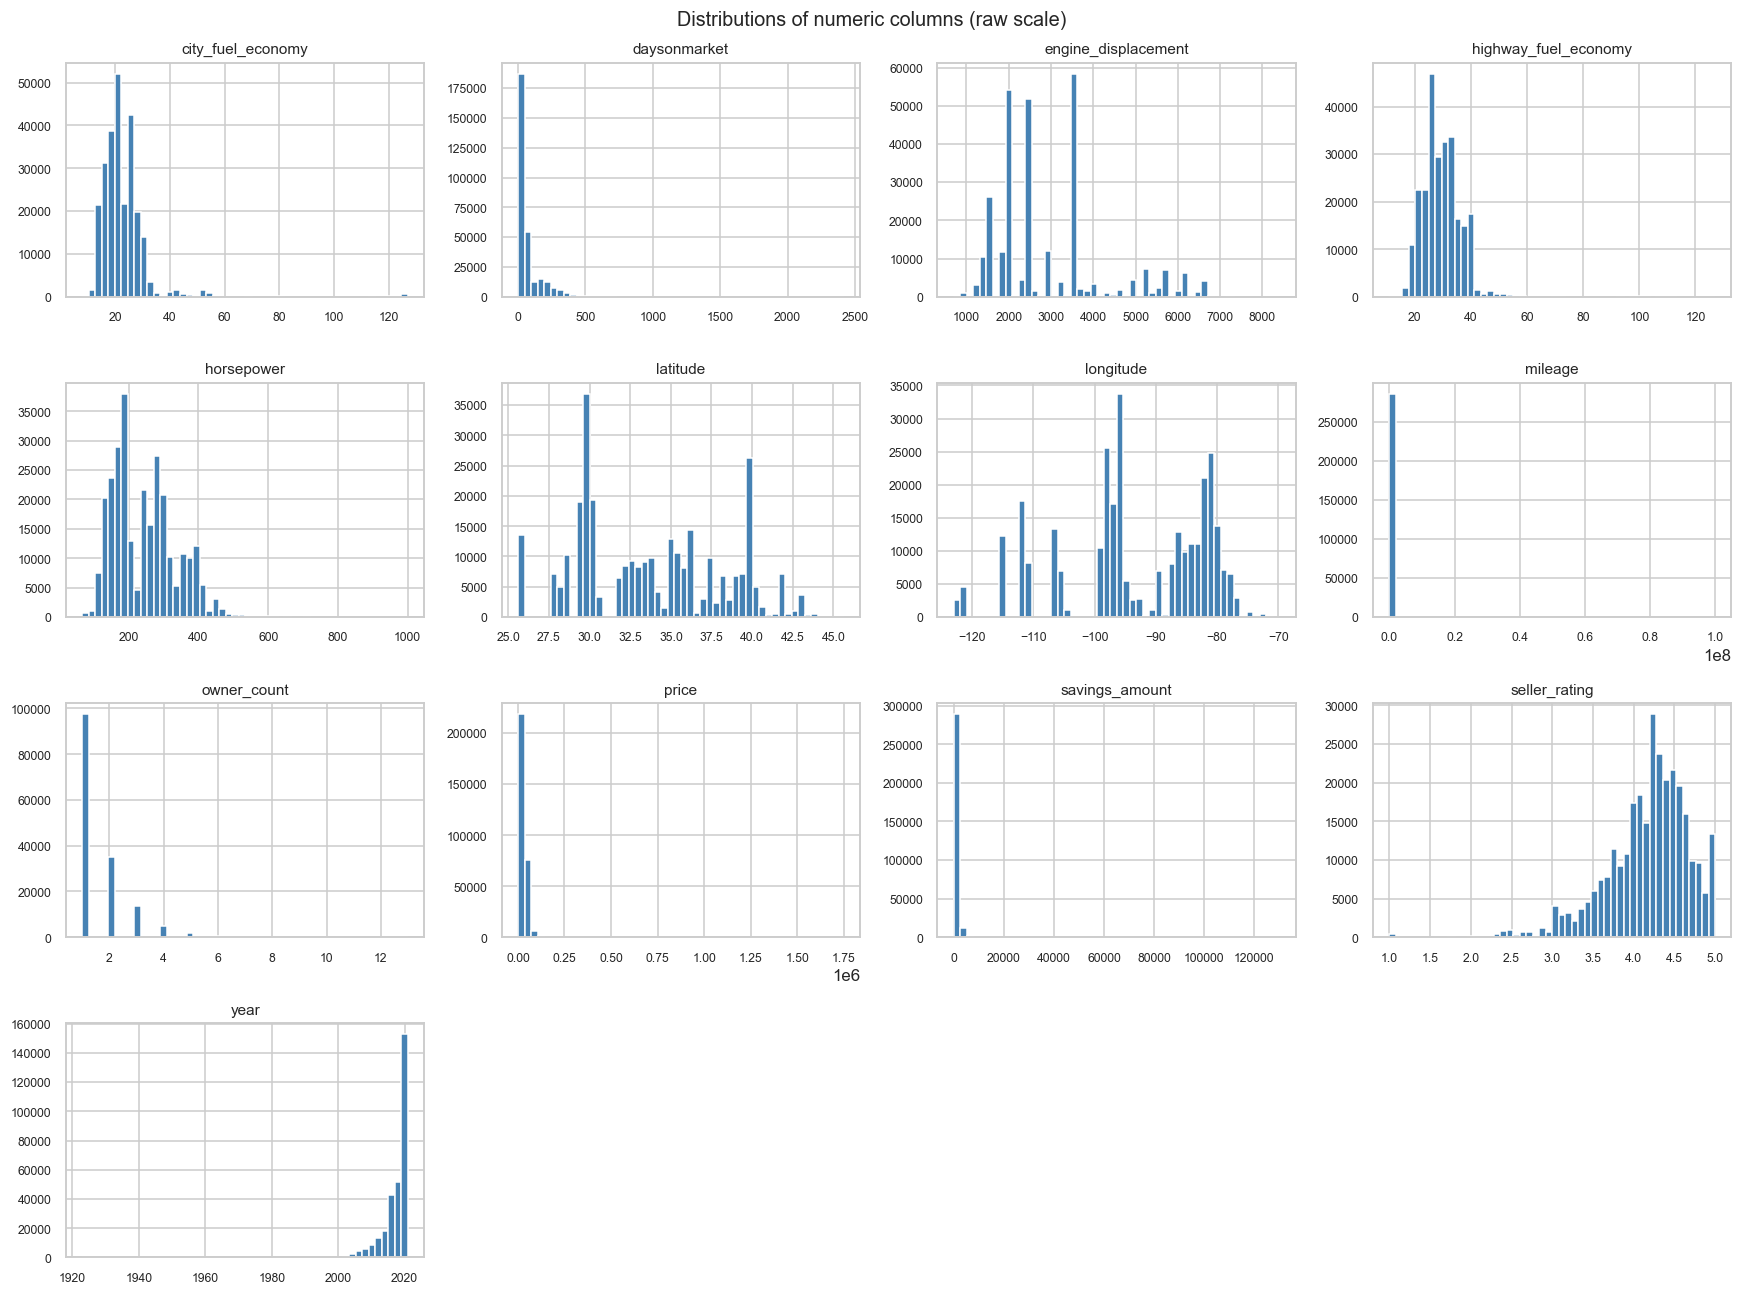

In [10]:
ncols = 4
nrows = int(np.ceil(len(num_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3 * nrows))
axes = axes.ravel()

for ax, c in zip(axes, num_cols):
    ax.hist(df[c].dropna(), bins=50, color="steelblue")
    ax.set_title(c, fontsize=10)
    ax.tick_params(labelsize=8)
for ax in axes[len(num_cols):]:      # hide unused panels
    ax.axis("off")

fig.suptitle("Distributions of numeric columns (raw scale)", fontsize=13)
fig.tight_layout()
plt.show()

Only 13 usable numeric columns survive — a reminder that the eight measurement columns from §4.2
are absent purely because of a formatting problem.

Almost every panel is a single spike against an empty axis, which is the signature of extreme
outliers, not of a degenerate variable: one value at 100M compresses all of mileage into the first
pixel, and savings_amount behaves the same way. year skews the other way, with a thin classic-car
tail reaching back to 1923. horsepower, seller_rating and the fuel-economy columns are the only
well-behaved ones.

### 5.2 The target: price

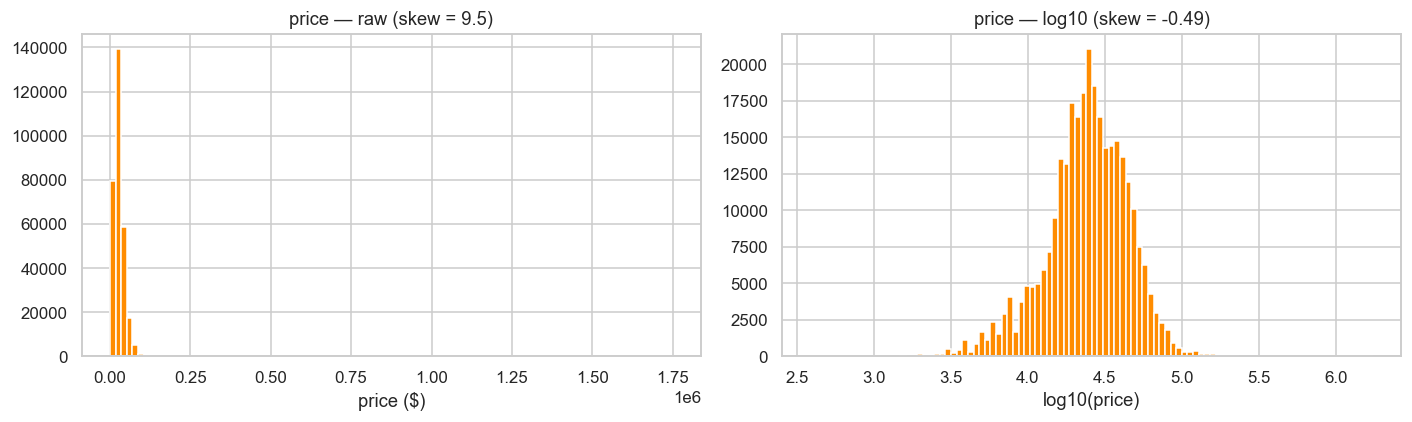

count     302590.0
mean       29125.0
std        20463.0
min          387.0
1%          4000.0
50%        25097.0
99%        87395.0
max      1750000.0


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df["price"], bins=100, color="darkorange")
axes[0].set_title(f"price — raw (skew = {df['price'].skew():.1f})")
axes[0].set_xlabel("price ($)")
axes[1].hist(np.log10(df["price"]), bins=100, color="darkorange")
axes[1].set_title(f"price — log10 (skew = {np.log10(df['price']).skew():.2f})")
axes[1].set_xlabel("log10(price)")
fig.tight_layout()
plt.show()

print(df["price"].describe(percentiles=[0.01, 0.5, 0.99]).round(0).to_string())

price is severely right-skewed (skew 9.5) and spans $386 to $1,750,000 — four orders of magnitude,
because a few Bugattis share the column with $400 beaters. On the log scale the skew falls to
-0.49 and the shape is near-symmetric.

Two consequences: squared-error models will be dominated by the handful of six-figure cars, so a log
target is worth testing in Notebook 3; and the 58 listings under $1,000 plus the 321 over $200,000 are
the rows most likely to need trimming. Note the brief requires price itself to stay unscaled on export.

### 5.3 Which columns have significant outliers?

In [12]:
rows = []
for c in num_cols:
    s = df[c].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    rows.append({
        "column": c,
        "pct_outliers": round(100 * int(((s < lo) | (s > hi)).sum()) / len(s), 2),
        "skew": round(s.skew(), 2),
        "max_over_p99": round(s.max() / s.quantile(0.99), 1) if s.quantile(0.99) > 0 else np.nan,
    })

pd.DataFrame(rows).sort_values("max_over_p99", ascending=False)

,column,pct_outliers,skew,max_over_p99
7,mileage,7.83,488.24,528.1
10,savings_amount,7.80,13.02,29.9
9,price,3.31,9.54,20.0
1,daysonmarket,13.80,3.76,5.1
8,owner_count,5.32,2.35,2.6
3,highway_fuel_economy,1.28,3.70,2.5
0,city_fuel_economy,2.98,5.86,2.4
4,horsepower,0.70,0.76,2.1
2,engine_displacement,4.27,1.13,1.3
5,latitude,0.00,0.19,1.1


max_over_p99 — the maximum divided by the 99th percentile — is the clearest indicator; a healthy
column sits near 1–2. mileage scores 528 and savings_amount 21, the numeric fingerprint of
the sentinel values in §4.4. price (20.0) and daysonmarket (5.8) are skewed but genuinely so.

That distinction drives the preprocessing choice: sentinel values should be deleted, real skew
should be transformed.

### 5.4 Categorical columns

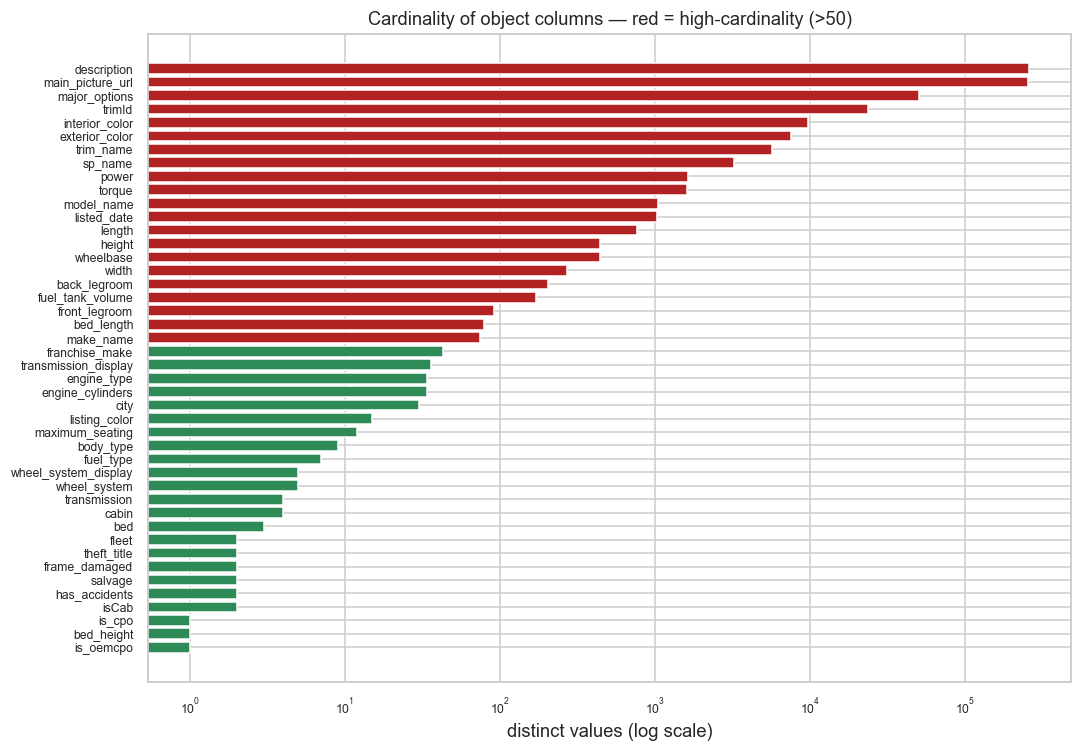

In [13]:
cat_card = df.select_dtypes("object").nunique().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 7))
colors = ["firebrick" if v > 50 else "seagreen" for v in cat_card]
ax.barh(cat_card.index[::-1], cat_card.values[::-1], color=colors[::-1])
ax.set_xscale("log")
ax.set_xlabel("distinct values (log scale)")
ax.set_title("Cardinality of object columns — red = high-cardinality (>50)")
ax.tick_params(labelsize=8)
fig.tight_layout()
plt.show()

The log scale splits the object columns into two populations. High-cardinality (red): description
(260,806), main_picture_url (254,865), major_options (50,632), trimId (23,808), interior_color
(9,731), exterior_color (7,604), trim_name (5,713), model_name (1,054).

One-hot encoding description alone would produce a quarter of a million columns on 302,590 rows —
more features than samples. This is exactly why the brief caps dummies at the top 20 categories.
major_options is a special case: it is a list stored as a string
("['Leather Seats', 'Bluetooth', ...]"), so its 50,632 "categories" are combinations of a much smaller
set of options. Parsed properly it becomes a compact set of binary features rather than a cardinality
problem.

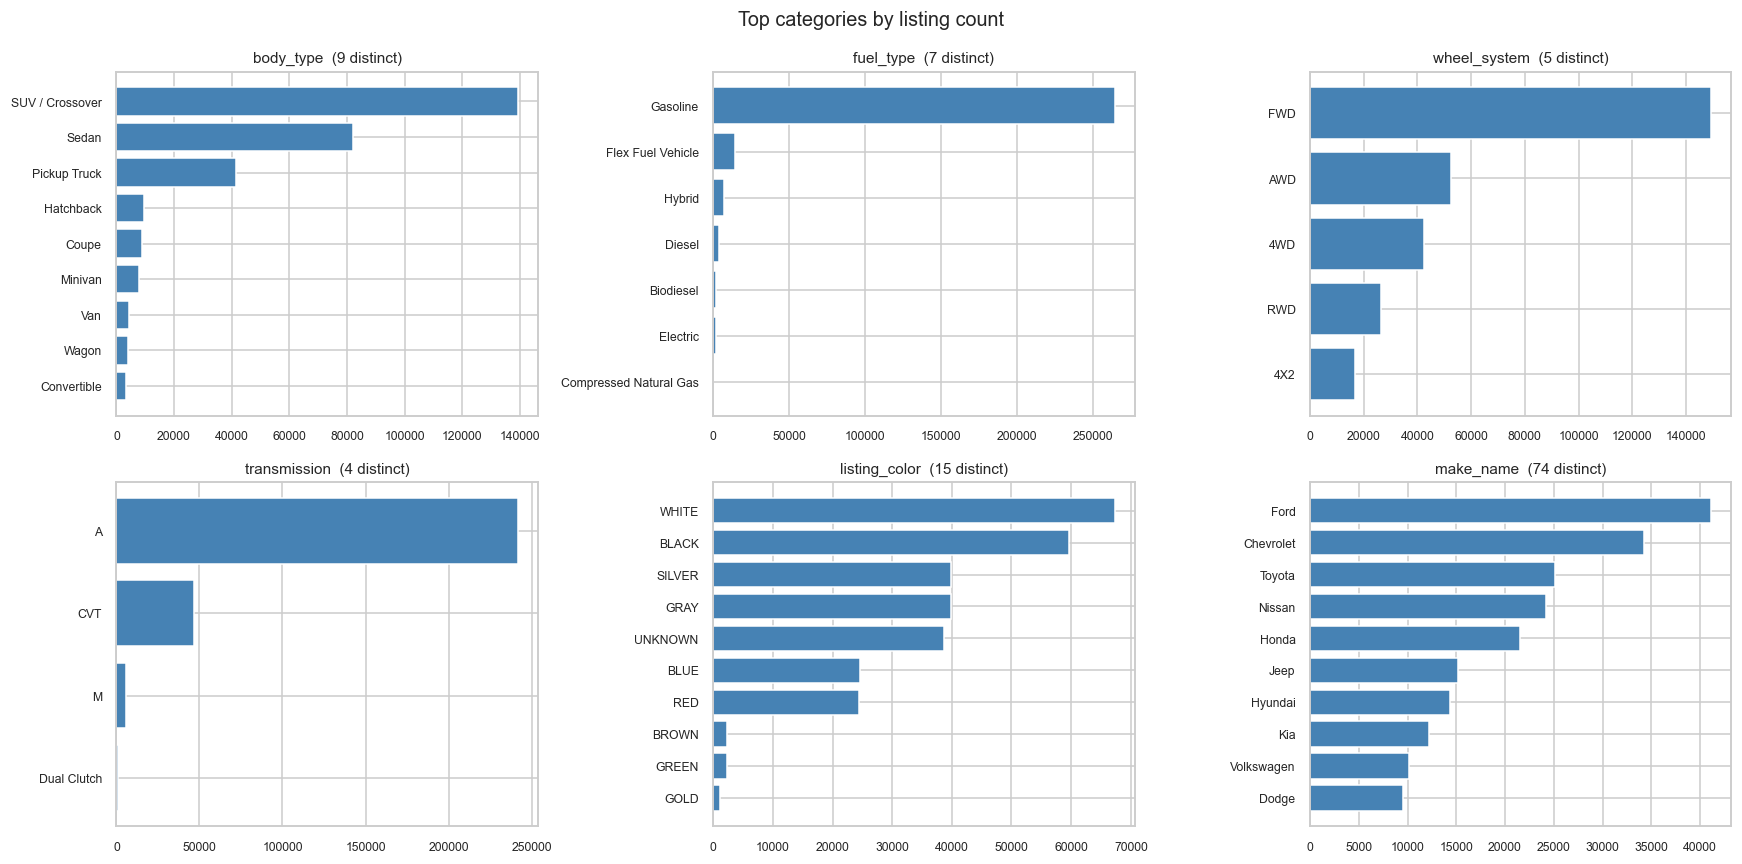

In [14]:
show = ["body_type", "fuel_type", "wheel_system", "transmission", "listing_color", "make_name"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), show):
    vc = df[c].value_counts().head(10)
    ax.barh(vc.index[::-1], vc.values[::-1], color="steelblue")
    ax.set_title(f"{c}  ({df[c].nunique()} distinct)", fontsize=10)
    ax.tick_params(labelsize=8)
fig.suptitle("Top categories by listing count", fontsize=13)
fig.tight_layout()
plt.show()

Every one is heavily imbalanced. SUVs and sedans are 73% of all listings; gasoline is 87% of
fuel_type, leaving Compressed Natural Gas with 15 rows; and make_name's 74 brands include several
with a single listing.

So rare categories will produce dummy columns that are almost entirely zero, and a split risks putting
all 15 CNG cars on one side. Grouping the tail into "Other" — which the top-20 rule does automatically —
handles both.

## 6. Bivariate relationships

### 6.1 What correlates with price?

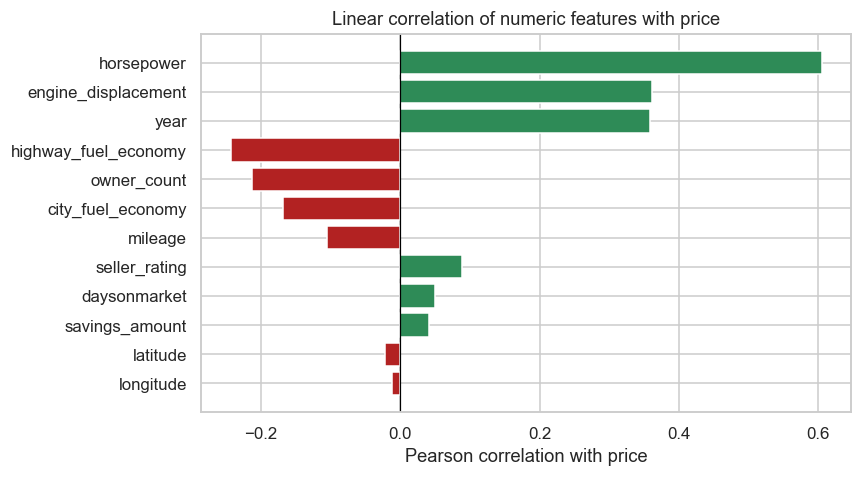

horsepower              0.605
engine_displacement     0.362
year                    0.358
highway_fuel_economy   -0.243
owner_count            -0.213
city_fuel_economy      -0.169
mileage                -0.106
seller_rating           0.089
daysonmarket            0.051
savings_amount          0.041
latitude               -0.022
longitude              -0.011
Name: price, dtype: float64

In [15]:
corr_price = (df[num_cols].corr(numeric_only=True)["price"]
              .drop("price").sort_values(key=abs, ascending=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(corr_price.index[::-1], corr_price.values[::-1],
        color=["seagreen" if v > 0 else "firebrick" for v in corr_price.values][::-1])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Pearson correlation with price")
ax.set_title("Linear correlation of numeric features with price")
fig.tight_layout()
plt.show()

corr_price.round(3)

horsepower is the strongest numeric predictor at r = 0.61, then engine_displacement (0.36) and
year (0.36). The negative side is intuitive: more economical cars, more previous owners, and more
miles all mean a cheaper car.

mileage at only -0.11 is the exception, and §4.4 already explained it — drop the 2 sentinel rows
and it becomes -0.45, which would make it the second-strongest predictor here. Its position in this
chart is understated by a data quality bug, not by a weak relationship. latitude/longitude sit near
zero, so raw coordinates carry no linear price signal, though location may still matter to a tree model.

Remember this chart uses 13 columns; the eight measurements stuck as strings (§4.2) are missing and may
rank highly once parsed.

### 6.2 Are those predictors correlated with each other?

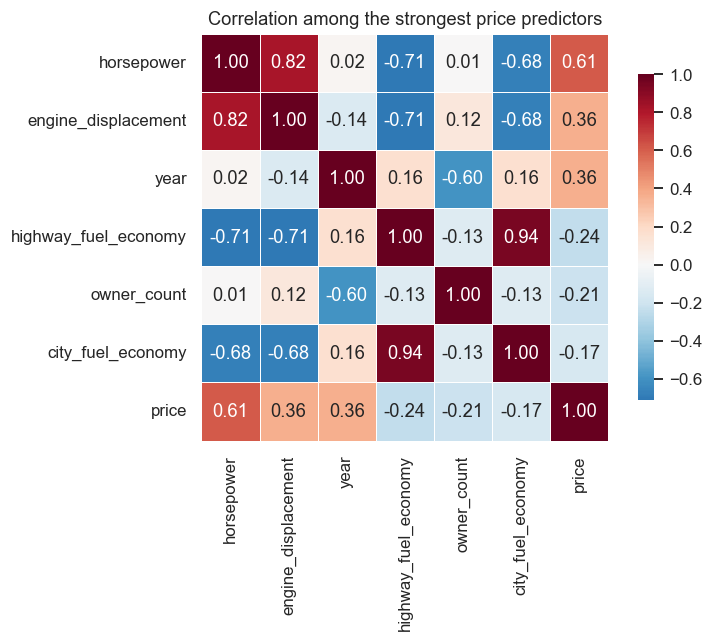

In [16]:
top_feats = corr_price.abs().head(6).index.tolist()

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(df[top_feats + ["price"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation among the strongest price predictors")
fig.tight_layout()
plt.show()

Yes — severely, and this is the most important finding for modelling. Three redundancies:

- city_fuel_economy ↔ highway_fuel_economy at r = 0.94 — almost the same variable.
- horsepower ↔ engine_displacement at 0.82 — bigger engines make more power.
- Both economy columns against both power columns at -0.68 to -0.71. All four are largely measuring
  one underlying "engine size" factor.
- year ↔ owner_count at -0.60, which is simply age.

For linear regression this multicollinearity means unstable, uninterpretable coefficients — the model
cannot separate horsepower from displacement when they move together. Tree models are unaffected. This
is precisely what the VIF step in Notebook 4 exists to catch, and we should expect it to drop one
member of each pair.

### 6.3 Price against the strongest predictors

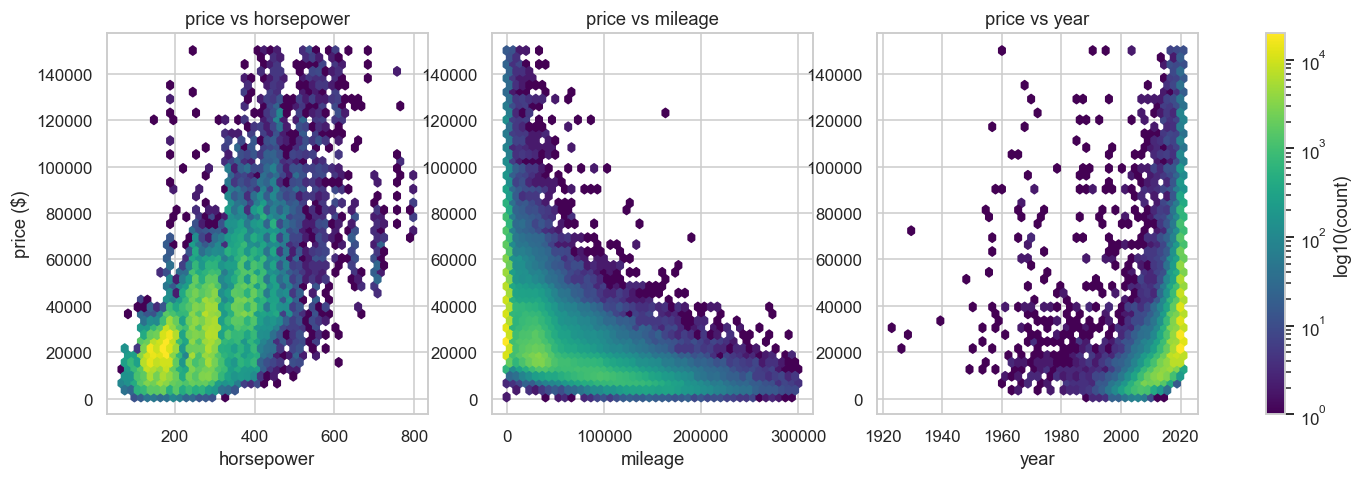

In [17]:
# Axis limits are for visualisation only — no rows are modified.
plot_df = df[(df["mileage"] < 300_000) & (df["price"] < 150_000)]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for i, (ax, c) in enumerate(zip(axes, ["horsepower", "mileage", "year"])):
    hb = ax.hexbin(plot_df[c], plot_df["price"], gridsize=45, cmap="viridis", bins="log", mincnt=1)
    ax.set_xlabel(c)
    ax.set_ylabel("price ($)" if i == 0 else "")
    ax.set_title(f"price vs {c}")
fig.colorbar(hb, ax=axes, label="log10(count)")
plt.show()

Density rather than scatter, because 302k overlapping points would show only a solid block.

- horsepower: positive and slightly convex — price rises faster than linearly at the high-power end.
- mileage: the classic depreciation curve, steep over the first ~50k miles then flattening. That
  curvature is why a single Pearson coefficient understates the relationship.
- year: the mass sits in 2017–2021 (2020 alone is 133,140 rows), and the pre-2010 region is too
  sparse for reliable estimates.

Both curved relationships point the same way: non-linear models should beat linear regression in
Notebook 3.

### 6.4 Price by category

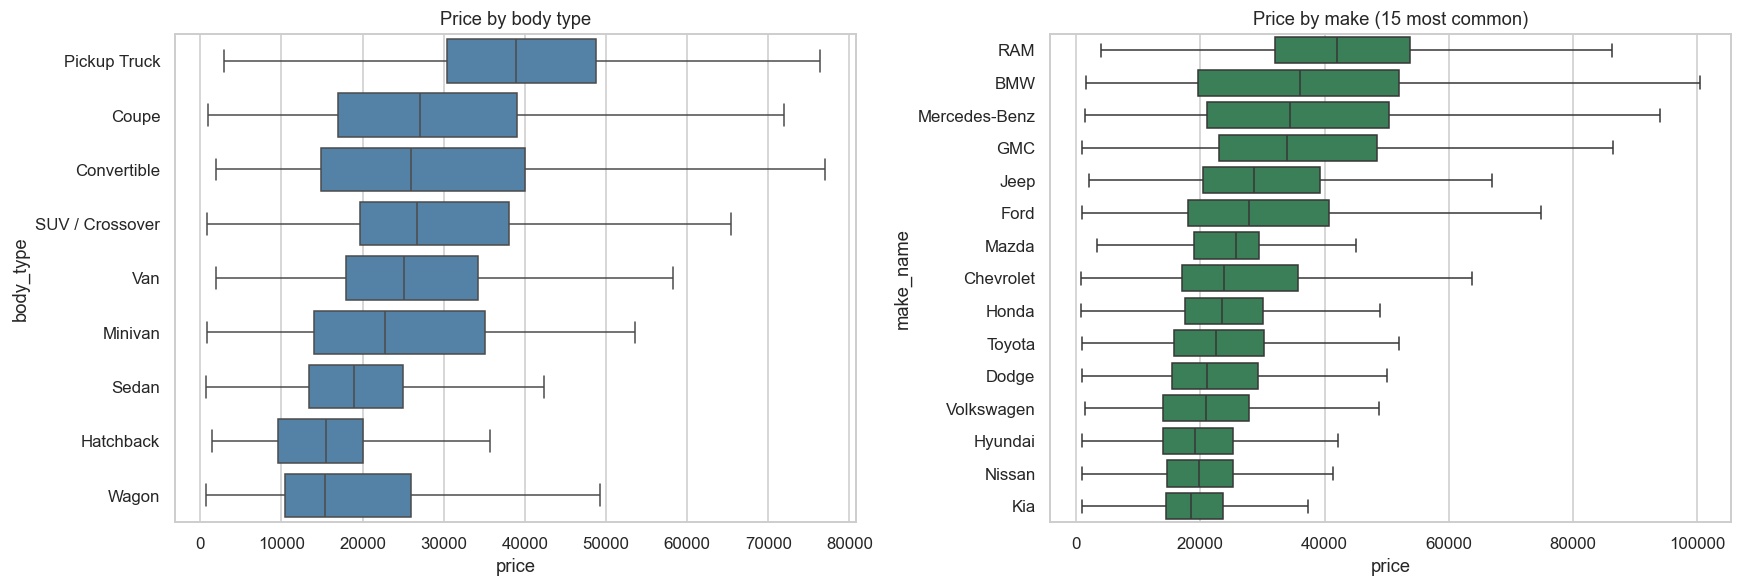

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

order = df.groupby("body_type")["price"].median().sort_values(ascending=False).index
sns.boxplot(data=plot_df, x="price", y="body_type", order=order,
            showfliers=False, color="steelblue", ax=axes[0])
axes[0].set_title("Price by body type")

top_makes = df["make_name"].value_counts().head(15).index
mk_order = (df[df["make_name"].isin(top_makes)]
            .groupby("make_name")["price"].median().sort_values(ascending=False).index)
sns.boxplot(data=plot_df[plot_df["make_name"].isin(top_makes)], x="price", y="make_name",
            order=mk_order, showfliers=False, color="seagreen", ax=axes[1])
axes[1].set_title("Price by make (15 most common)")

fig.tight_layout()
plt.show()

Both separate price strongly, so both are worth encoding.

Body type spans a 2.5× range in medians, from Pickup Truck at $39,060 down to Wagon at $15,498.
The truck result is the interesting one — trucks are not luxury goods, but these listings skew recent
and high-displacement, consistent with engine_displacement being the #2 numeric predictor.

Make is only partly the premium ordering you would expect. BMW and Mercedes-Benz sit near the top
and Kia, Nissan, Hyundai at the bottom — but the highest median of the 15 is RAM, with GMC close
behind. Both are truck brands, reinforcing the body-type result: here "expensive" tracks trucks at
least as much as luxury badges. (These are the most common makes, so genuine exotics are excluded by
design — they are the long tail from §5.4.)

The boxes are wide, though: within-make spread exceeds most between-make gaps, so make_name alone is
a coarse predictor and needs year/mileage/horsepower alongside it.

## 7. Data Quality Register — hand-off to Notebook 2

In [19]:
register = pd.DataFrame([
    ("§2",   "3 columns 100% missing",              "combine_fuel_economy, is_certified, vehicle_damage_category", "Drop"),
    ("§2",   "History-report block, 46.1% missing", "fleet, frame_damaged, has_accidents, isCab, salvage, theft_title", "Missing is informative — encode as its own level, do not impute False"),
    ("§2",   "Truck-only fields, 87-99% missing",   "bed, bed_length, cabin",                                 "Structurally missing — encode 'not applicable'"),
    ("§3",   "Identifier / free-text columns",      "Unnamed: 0, listing_id, sp_id, main_picture_url, description", "Drop"),
    ("§3",   "Label leakage",                       "savings_amount",                                         "Drop — derived from price"),
    ("§3",   "Exact redundancy",                    "wheel_system_display",                                   "Drop — 1-to-1 with wheel_system"),
    ("§3",   "ZIP read as an integer magnitude",    "dealer_zip",                                             "Drop or cast to category"),
    ("§4.1", "'--' not caught by isna()",           "9 columns incl. back_legroom (8,750), bed_height (all)",  "Replace '--' with NaN BEFORE any null handling"),
    ("§4.2", "Numerics stored as strings w/ units", "back_legroom, front_legroom, fuel_tank_volume, height, length, wheelbase, width, maximum_seating", "Strip suffix, cast to float (handle '--' first)"),
    ("§4.2", "Two values packed in one string",     "power, torque",                                          "Split into value + RPM; hp half duplicates horsepower"),
    ("§4.3", "Booleans stored 3 different ways",    "fleet, salvage, has_accidents (object); is_certified (float)", "Normalise to one boolean dtype"),
    ("§4.3", "One-sided flags: True or NaN",        "is_cpo, is_oemcpo",                                      "NaN means False for these two specifically"),
    ("§4.4", "Odometer sentinel 99,999,988",        "mileage",                                                "Drop rows > 500,000 miles (2 rows; std -76%, corr -0.11 -> -0.45)"),
    ("§4.4", "MPG and MPGe mixed in one column",    "city_fuel_economy, highway_fuel_economy",                "Separate EV MPGe; 74 gasoline rows >60 mpg are errors"),
    ("§4.5", "1,210 content-duplicate rows",        "all columns",                                            "Deduplicate ignoring the key columns, BEFORE splitting"),
    ("§4.5", "is_new contradicts mileage/year",     "is_new, mileage, year",                                  "4,406 rows — do not derive one field from the other"),
    ("§4.5", "'UNKNOWN' string used as missing",    "listing_color (38,740 rows)",                            "Treat as missing or keep as an explicit level"),
    ("§4.5", "Free-text colour, 7,604 values",      "exterior_color, interior_color",                          "Map to the clean 15-value listing_color"),
    ("§4.5", "Date stored as a string",             "listed_date",                                            "Parse to datetime, derive age features"),
    ("§5.2", "Target skew 9.5, range 386-1.75M",    "price",                                                  "Trim extremes; test log target in NB3 (price stays unscaled on export)"),
    ("§5.4", "High cardinality",                    "major_options (50,632), trimId, interior_color, exterior_color, trim_name, model_name", "major_options is a stringified list — parse to binary flags; cap others at top 20"),
    ("§5.4", "Rare categories",                     "fuel_type (CNG = 15 rows), make_name tail",              "Group tail into 'Other'"),
    ("§6.2", "Multicollinearity",                   "city/highway fuel economy r=0.94; horsepower/displacement r=0.82", "Expect VIF filtering in NB4 to drop one of each pair"),
], columns=["found_in", "issue", "columns_affected", "recommended_action"])

register

,found_in,issue,columns_affected,recommended_action
0,§2,3 columns 100% missing,"combine_fuel_economy, is_certified, vehicle_da...",Drop
1,§2,"History-report block, 46.1% missing","fleet, frame_damaged, has_accidents, isCab, sa...",Missing is informative — encode as its own lev...
2,§2,"Truck-only fields, 87-99% missing","bed, bed_length, cabin",Structurally missing — encode 'not applicable'
3,§3,Identifier / free-text columns,"Unnamed: 0, listing_id, sp_id, main_picture_ur...",Drop
4,§3,Label leakage,savings_amount,Drop — derived from price
5,§3,Exact redundancy,wheel_system_display,Drop — 1-to-1 with wheel_system
6,§3,ZIP read as an integer magnitude,dealer_zip,Drop or cast to category
7,§4.1,'--' not caught by isna(),"9 columns incl. back_legroom (8,750), bed_heig...",Replace '--' with NaN BEFORE any null handling
8,§4.2,Numerics stored as strings w/ units,"back_legroom, front_legroom, fuel_tank_volume,...","Strip suffix, cast to float (handle '--' first)"
9,§4.2,Two values packed in one string,"power, torque",Split into value + RPM; hp half duplicates hor...


## 8. Summary

Structure. 302,590 listings × 66 columns, but only 13 are usable numerics as loaded. Missingness is
highly structured — a 46.10% block from unpulled history reports, an 87–99% block of truck-only fields —
so why a value is missing matters more than how much is missing.

Data quality. 23 issues are registered in §7. The two that would quietly break a naive pipeline are
the "--" placeholder, which isna() does not detect and which will crash the numeric parse, and the
odometer sentinel — just 2 rows, but they inflate mileage's standard deviation four-fold and cut its
correlation with price from -0.45 to -0.11. Eight genuine measurements are trapped as strings, and
1,210 duplicate rows must go before the train/test split to avoid leakage.

Distributions. price is severely right-skewed (skew 9.5, $386–$1.75M) and near-symmetric in log
space. Categoricals are heavily imbalanced, and several are high-cardinality enough that unrestricted
one-hot encoding would produce more features than rows.

Relationships. horsepower leads at r = 0.61, ahead of engine_displacement and year (0.36).
The predictors are badly collinear with each other — fuel economy pair at 0.94, horsepower and
displacement at 0.82 — which sets up the VIF filtering in Notebook 4. body_type and make_name both
separate price strongly. The price–mileage and price–horsepower relationships are visibly curved, so
tree-based models should outperform linear regression.

Next. Notebook 2 works through the §7 register in order, reading the raw CSV fresh rather than
carrying anything over from here.